# <span style="color:red"> DATASCI 151 - Practice Quiz #3 </span>

______________________

<font size = "4">

**Question (A)** Piecewise-defined function


<font size = "3">

Recall the following piecewise-defined expression from Practice Quiz #2

$$
y = 
\begin{cases}
0 & \text{if } x \le 0 \\[6pt]
\dfrac{1}{2}x & \text{if } 0 < x \le \tfrac{1}{2} \\[10pt]
\dfrac{1}{2}(1 - x) & \text{if } \tfrac{1}{2} < x \le 1 \\[6pt]
0 & \text{if } 1 < x
\end{cases}
$$

One way to implement this expression is as follows (using a randomly generated value for $x$):

In [1]:
import random 

x = random.uniform(-0.5, 1.5)

# SOLUTION
y = 0
if 0 < x <= 0.5:
    y = 0.5*x
elif 0.5 < x <= 1:
    y = 0.5*(1 - x)

print(y)

0


<font size = "4">

Using the code above, write a **function** that takes in a floating point number `x` and returns a floating point number `y` defined by the expression above.

In [2]:
# Write your function here

def piecewise(x): 
    y = 0
    if 0 < x <= 0.5:
        y = 0.5*x
    elif 0.5 < x <= 1: 
        y = 0.5 * (1 - x)
    return y

______________________

<font size = "4">

**Question (B)** Quadratic Formula


<font size = "3">

Consider solving the quadratic equation $ax^2 + bx + c = 0$. In addition to the standard quadratic formula, the following is an equivalent way of expressing the two solutions:

$$ x = \frac{2c}{-b \mp \sqrt{b^2 - 4ac}}$$

1. Write a function called `alt_quad_formula` that takes in 3 input arguments corresponding to the coefficients $a$, $b$, and $c$ and returns the two solutions to the corresponding quadratic equation computed using the expression above.

2. Test your function on the quadratic equation $3(x + 1)(x - 2) = 0$, verifying you get the outputs $-1$ and $2$.

In [3]:
import numpy as np
### Your solution below

def alt_quad_formula(a, b, c):
    x_pos = (2*c)/(-b+np.sqrt((b**2)-(4*a*c)))
    x_neg = (2*c)/(-b-np.sqrt((b**2)-(4*a*c)))
    return x_pos, x_neg

x1, x2 = alt_quad_formula(a = 3, b = -3, c = -6)
print(x1)
print(x2)




-1.0
2.0


______________________

<font size = "4">

**Question (C)** For loop with a break statement

<font size = "3">

With the random library, you can simulate a dice roll by randomly generating an integer between 1 and 6, using the line of code 

 ``` python
roll = random.choice([1,2,3,4,5,6])
```
(you can choose a different variable name than "roll" of course).

We will simulate the following game. Each turn, you roll **TWO** six-sided dice. You want to stop as soon as you roll doubles (both dice show the same number), but you will give up after `max_rolls` turns. Write a `for` loop with a `break` statement so that:

- If you roll doubles, the string "Doubles on roll {k}!" where "k" is the turn number (the first turn is turn 1, **not** turn 0).

- After `max_rolls` turns, if you haven't rolled doubles yet, print "No doubles in {max_rolls} rolls".

Your code should work even if the value of "max_rolls" is changed at the top of the code cell.

**Hint:** It might be a good idea to work in stages. In a scratch cell, figure out how to write the code that simulates a single roll of two dice, and checks if a double is rolled. Then try writing the for loop.

In [8]:
max_rolls = 4

# Your code here

import random

for i in range(max_rolls): 
    roll_1 = random.choice([1,2,3,4,5,6])
    roll_2 = random.choice([1,2,3,4,5,6])
    if roll_1 == roll_2:
        print("Doubles on roll", i+1, "!")
        break
    if i == max_rolls - 1: 
        print("No doubles in", max_rolls, "rolls")


Doubles on roll 3 !


______________________

<font size = "4">

**Question (D)** Computing the mean value of filtered data

<font size = "3">

A temperature sensor in a warehouse records the temperature in Celsius every 30 minutes. Occasionally, the sensor "glitches" and return values that are unreasonable. For this problem, any item **outside** the range $\textrm{min\_val} \leq \textrm{item} \leq \textrm{max\_val}$ is "unreasonable".

Write a for loop that iterates over the items in `temp_data` and computes the average value of all **reasonable** data values, ignoring the others. 

Implement **two** versions of your solution: (i) one that utilizes the "continue" keyword, and (ii) one that doesn't.




In [9]:
temp_data = [-5, -2, 0, 1000, 2, -12, 44, 40, 30, -10]
min_val = -10
max_val = 40

# here is what you should get for both approaches
approach_1_expected = (-5 + (-2) + 0 + 2 + 40 + 30 + (-10)) / 7


# Your code here
reasonable_sum = 0
reasonable_count = 0

for i in temp_data:
    if (min_val > i) or (i > max_val):
        continue

    reasonable_sum = reasonable_sum + i
    reasonable_count = reasonable_count + 1

average = reasonable_sum/reasonable_count
print(average)

# without using continue

sum = 0
count = 0
for i in temp_data: 
    if min_val <= i <= max_val:
        sum = sum + i
        count = count + 1

mean = sum/count
print(mean)



7.857142857142857
7.857142857142857


______________________

<font size = "4">

**Question (E)** Equivalent interest rates

<font size = "3">

**NOTE:** For this problem, interest rates are always given in decimal form. An interest rate of 25% corresponds to $r = 0.25$, an interest rate of 5% corresponds to $r = 0.05$, etc.

Suppose you have a nominal annual interest rate $r_1$ that is compounded $n_1$ times per year. Then the value of $1 after one year is given by:

$$ \left(1 + \frac{r_1}{n_1} \right)^{n_1}$$

Let $r_2$ denote the **equivalent** nominal annual interest rate compounded $n_2$ times per year. Then the value of a dollar after one year should be the same:

$$ \left(1 + \frac{r_2}{n_2} \right)^{n_2} = \left(1 + \frac{r_1}{n_1} \right)^{n_1}$$

Solving for $r_2$, we get:

\begin{align}
 r_2 = n_2\cdot \left[ \left(1 + \frac{r_1}{n_1} \right)^{\frac{n_1}{n_2}} - 1 \right]
 \end{align}

- Using the equation above as a guide, write a function which calculates the value of $r_2$ based on the values of $r_1$, $n_1$, and $n_2$ 

- Then evaluate the function to determine the nominal annual rate, compounded monthly ($n_2 = 12$), that is equivalent to a 10% nominal annual rate compounded daily ($n_1 = 365$).


**NOTE: Read the note at the top of this question.**

In [12]:
# Your solution here

def equivalent(r1, n1, n2):
    exponent = n1/n2
    bracket = ((1+(r1/n1))**exponent) - 1
    r2 = n2 * bracket
    return r2

print(equivalent(0.1, 365, 12))

0.10040401575731028


______________________

<font size = "4">

**Question (F)** Function with no return value

<font size = "3">

<p>Write a function that does <strong>not return any values</strong> (just like the <code>print</code> function).</p>
<p>The function takes in <strong>4 arguments</strong>, with the following keywords:</p>
<ul>
<li><code>x_vals</code>: A sequence of numeric values (list, tuple, NumPy array, etc.)</li>
<li><code>y_vals</code>: A sequence of numeric values of the same length as <code>x_vals</code></li>
<li><code>x_label</code>: A string</li>
<li><code>y_label</code>: A string</li>
</ul>
<p>The function creates a <strong>scatter plot</strong> of <code>x_vals</code> versus <code>y_vals</code>.<br>
It should:</p>
<ul>
<li>Label the x-axis using <code>x_label</code></li>
<li>Label the y-axis using <code>y_label</code></li>
<li>Display the plot to the screen</li>
</ul>
<p>The function should have <strong>no return values</strong>.<br>
(You may omit a return statement or explicitly write <code>return None</code>.)</p>
</font></font>

<font size = "3">

After defining your function in the first cell below, read in the file "us_emission.csv" from the folder "quiz_data" and call your function twice to generate the **two** following scatter plots:

1. "Energy Consumption" vs. "CO2 Emissions"
    
2. "Year" vs. "CO2 Emissions"

In [13]:
import matplotlib.pyplot as plt

# Your function here
def scatter(x_vals, y_vals, x_label, y_label):
    plt.scatter(x_vals,y_vals)
    plt.xlabel(x_label)
    plt.ylabel(y_label)
    plt.show()


Index(['Year', 'Energy_consumption', 'CO2_emission', 'GDP'], dtype='str')


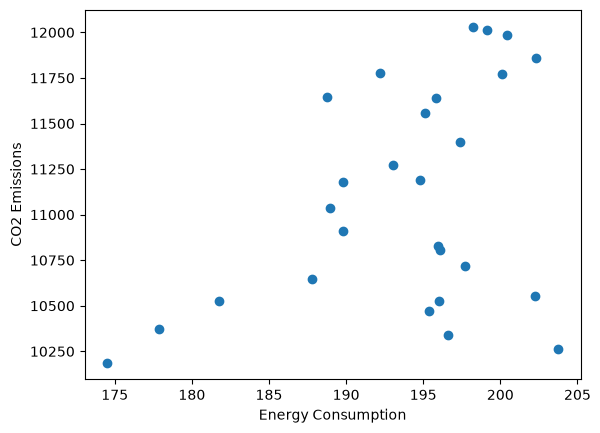

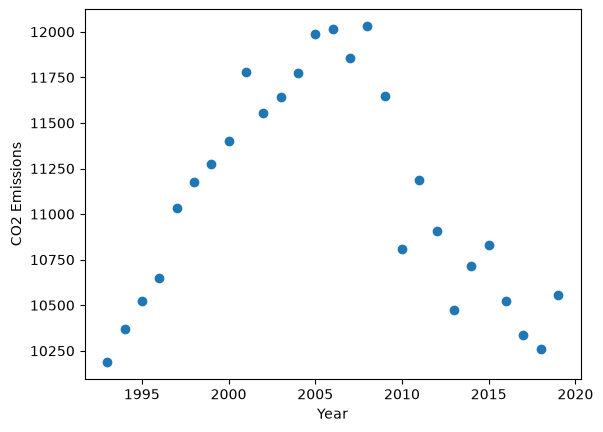

In [17]:
import pandas as pd

# read in the us_emission.csv dataset, and call your function twice to generate two scatter plots
data = pd.read_csv("quiz_data/us_emission.csv")

# energy consumption vs. co2 emissions
print(data.columns)

scatter(data['Energy_consumption'], data['CO2_emission'], 'Energy Consumption', 'CO2 Emissions')

# year vs. co2 emissions

scatter(data['Year'], data['CO2_emission'], 'Year', 'CO2 Emissions')
